# Análisis del ETF QQQ (Invesco QQQ Trust)
**Taller de Ingeniería Económica — entrega 31 de octubre de 2026**

Este notebook analiza un solo activo, el ETF **QQQ**, que replica el índice **Nasdaq-100**: las ~100 empresas no financieras más grandes que cotizan en la bolsa Nasdaq.

**Contenido**
1. **Composición del ETF**: qué empresas lo forman, cuánto pesa cada una, sectores y datos del fondo.
2. **Pronóstico con varios modelos predictivos** y comparación entre ellos.
3. **Cadena de suministro** y relación causa-efecto: por qué sube o baja la cotización.

**Fuentes**
- Composición oficial: Invesco (administrador del fondo), invesco.com/qqq-etf, pestaña *Holdings*, archivo *Complete Holdings*.
- Precios históricos, sectores y verificación cruzada: Yahoo Finance (librería `yfinance`).

In [1]:
# Solo en Google Colab: descarga los datos del repositorio (en un computador no hace nada)
import sys
if "google.colab" in sys.modules:
    !git clone -q https://github.com/Chaparroo/analisis-qqq-ingenieria-economica-.git
    %cd analisis-qqq-ingenieria-economica-
    %pip install -q yfinance

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

warnings.filterwarnings("ignore", message="The inplace keyword")  # avisos internos de yfinance

TICKER = "QQQ"
HOLDINGS_CSV = Path("datos/holdings_qqq_invesco_2026-10-23.csv")  # descargado de invesco.com/qqq-etf
SECTORES_CSV = Path("datos/sectores_qqq.csv")  # se crea solo la primera vez (consulta Yahoo Finance)

# Estilo común de las gráficas
AZUL = "#2a78d6"
GRIS = "#898781"
TEXTO = "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TEXTO,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "grid.color": "#e1e0d9",
    "font.size": 11,
})

## 1. Composición del ETF

### 1.1 Lectura del archivo oficial de Invesco
El archivo trae una fila por cada posición del fondo. Además de acciones, incluye **efectivo y futuros** (contratos sobre el índice que el fondo usa para invertir el efectivo que entra mientras compra acciones). Para analizar la composición nos quedamos solo con las **acciones** (incluidas las ADR, que son acciones de empresas extranjeras negociadas en EE.UU., como ASML o ARM).

Columnas importantes:
- **% TNA** (*Total Net Assets*): porcentaje del fondo que ocupa esa posición, es decir, su **peso**.
- **Market value**: valor en dólares de esa posición.

In [3]:
raw = pd.read_csv(HOLDINGS_CSV, comment="#", encoding="utf-8-sig")
fecha_datos = HOLDINGS_CSV.read_text(encoding="utf-8-sig").strip().splitlines()[-1].replace("# as of", "").strip()

raw["peso_pct"] = pd.to_numeric(raw["% TNA"].str.rstrip("%"), errors="coerce")
raw["valor_usd"] = pd.to_numeric(raw["Market value"].str.replace(r"[$,]", "", regex=True), errors="coerce")

ACCIONES = ["Common Stock", "American Depository Receipt", "American Depository Receipt - NY"]
es_accion = raw["Class of shares"].isin(ACCIONES)

holdings = (
    raw[es_accion]
    .rename(columns={"Ticker": "ticker", "Company": "empresa", "Class of shares": "tipo"})
    [["ticker", "empresa", "tipo", "peso_pct", "valor_usd"]]
    .sort_values("peso_pct", ascending=False)
    .reset_index(drop=True)
)

print(f"Datos de Invesco al: {fecha_datos}")
print(f"Posiciones en acciones: {len(holdings)}")
print("\nPosiciones que NO son acciones (efectivo, futuros, dividendos por cobrar):")
display(raw.loc[~es_accion, ["Ticker", "Company", "Class of shares", "% TNA", "Market value"]])

Datos de Invesco al: 2026-10-23
Posiciones en acciones: 101

Posiciones que NO son acciones (efectivo, futuros, dividendos por cobrar):


,Ticker,Company,Class of shares,% TNA,Market value
96,USD,CASH & EQUIVALENTS,Currency,0.14%,"$661,358,464.11"
98,NQZ6,CME E-Mini NASDAQ 100 Index Future,Index Future,0.14%,"$655,149,375"
103,--,CASH COLLATERAL,Currency Collateral,0.01%,"$39,673,721.75"
104,--,CONTRA FUTURE FUTURE DEC 18 26,Synthetic Cash,-0.14%,"-$655,149,375"
105,USDPDV,USD Pending Dividends,Currency,--,"$29,201,442.39"


### 1.2 Peso de cada empresa y concentración
Algunas empresas tienen **dos tipos de acción** en el fondo (por ejemplo Alphabet: GOOGL con voto y GOOG sin voto). Para medir cuánto depende el ETF de cada empresa las sumamos.

La **concentración** responde: ¿cuántas empresas explican la mayor parte del fondo? Si pocas empresas pesan mucho, el precio de QQQ depende sobre todo de lo que les pase a ellas.

In [4]:
empresas = (
    holdings.groupby("empresa", as_index=False)
    .agg(peso_pct=("peso_pct", "sum"), valor_usd=("valor_usd", "sum"), tickers=("ticker", ", ".join))
    .sort_values("peso_pct", ascending=False)
    .reset_index(drop=True)
)
empresas.index = empresas.index + 1  # ranking desde 1
acumulado = empresas["peso_pct"].cumsum()

resumen = pd.Series({
    "Fecha de los datos": fecha_datos,
    "Posiciones en acciones (tickers)": len(holdings),
    "Empresas distintas": len(empresas),
    "Valor total en acciones (miles de millones USD)": round(holdings["valor_usd"].sum() / 1e9, 1),
    "Peso de la empresa #1 (%)": round(empresas["peso_pct"].iloc[0], 2),
    "Peso de las 5 mayores (%)": round(acumulado.iloc[4], 2),
    "Peso de las 10 mayores (%)": round(acumulado.iloc[9], 2),
    "Peso de las 20 mayores (%)": round(acumulado.iloc[19], 2),
    "Empresas necesarias para llegar al 50% del fondo": int((acumulado < 50).sum() + 1),
}, name="valor")
display(resumen.to_frame())

tabla_top = empresas.head(15).assign(
    peso_acumulado_pct=acumulado.head(15).round(2),
    valor_miles_millones_usd=(empresas["valor_usd"].head(15) / 1e9).round(1),
)[["empresa", "tickers", "peso_pct", "peso_acumulado_pct", "valor_miles_millones_usd"]]
display(tabla_top)

,valor
Fecha de los datos,2026-10-23
Posiciones en acciones (tickers),101
Empresas distintas,100
Valor total en acciones (miles de millones USD),475.2
Peso de la empresa #1 (%),8.1
Peso de las 5 mayores (%),32.52
Peso de las 10 mayores (%),49.42
Peso de las 20 mayores (%),67.39
Empresas necesarias para llegar al 50% del fondo,11


,empresa,tickers,peso_pct,peso_acumulado_pct,valor_miles_millones_usd
1,NVIDIA Corp,NVDA,8.10,8.10,38.5
2,Apple Inc,AAPL,8.08,16.18,38.5
3,Microsoft Corp,MSFT,6.20,22.38,29.5
4,Alphabet Inc,"GOOGL, GOOG",5.78,28.16,27.5
5,Micron Technology Inc,MU,4.36,32.52,20.7
6,Amazon.com Inc,AMZN,4.26,36.78,20.3
7,Advanced Micro Devices Inc,AMD,3.71,40.49,17.6
8,Tesla Inc,TSLA,3.11,43.60,14.8
9,Meta Platforms Inc,META,3.04,46.64,14.5
10,Space Exploration Technologies Corp,SPCX,2.78,49.42,13.2


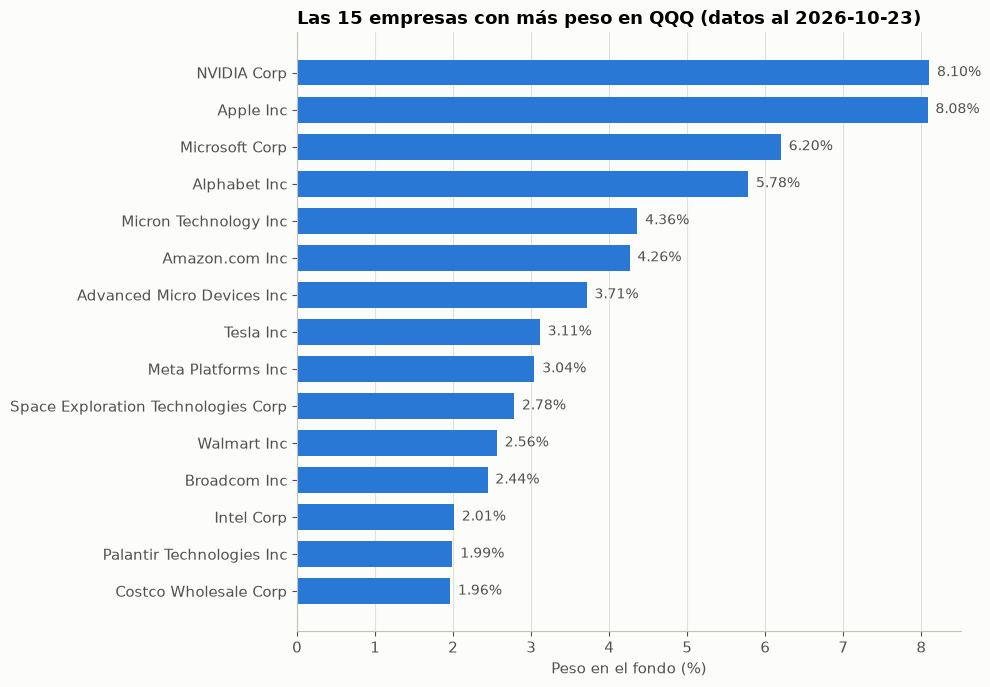

In [5]:
top = empresas.head(15).iloc[::-1]  # al revés para que la mayor quede arriba

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["empresa"], top["peso_pct"], color=AZUL, height=0.7)
for y, valor in enumerate(top["peso_pct"]):
    ax.text(valor + 0.1, y, f"{valor:.2f}%", va="center", color=TEXTO, fontsize=10)
ax.set_xlabel("Peso en el fondo (%)")
ax.set_title(f"Las 15 empresas con más peso en {TICKER} (datos al {fecha_datos})", loc="left")
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

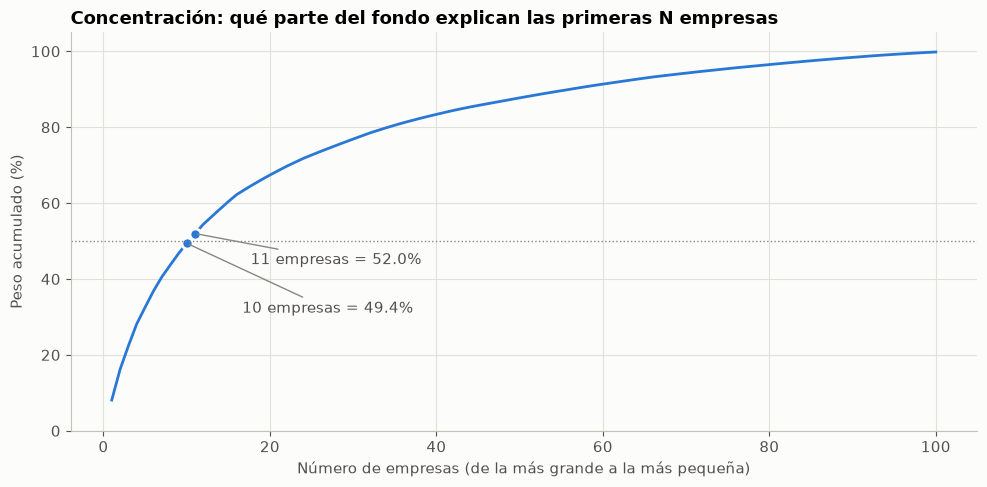

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(acumulado.index, acumulado.values, color=AZUL, linewidth=2)
n_50 = int((acumulado < 50).sum() + 1)
for n, desplazamiento in ((10, (40, -50)), (n_50, (40, -22))):
    ax.plot(n, acumulado.loc[n], "o", color=AZUL, markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{n} empresas = {acumulado.loc[n]:.1f}%", (n, acumulado.loc[n]),
                xytext=desplazamiento, textcoords="offset points", color=TEXTO,
                arrowprops={"arrowstyle": "-", "color": GRIS, "linewidth": 1})
ax.axhline(50, color=GRIS, linestyle=":", linewidth=1)
ax.set_xlabel("Número de empresas (de la más grande a la más pequeña)")
ax.set_ylabel("Peso acumulado (%)")
ax.set_ylim(0, 105)
ax.set_title("Concentración: qué parte del fondo explican las primeras N empresas", loc="left")
ax.grid(True)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 1.3 Sectores, industrias y países
El archivo de Invesco no trae el sector de cada empresa, así que lo consultamos en Yahoo Finance empresa por empresa. La primera vez tarda 1-2 minutos y el resultado se guarda en `datos/sectores_qqq.csv`; las siguientes veces se lee de ese archivo. Para actualizarlo, borra el archivo y vuelve a correr la celda.

La **industria** es más detallada que el sector (por ejemplo, el sector *Tecnología* incluye las industrias *Semiconductores*, *Software* y *Hardware*). La usaremos en la parte 3 para armar la cadena de suministro.

In [7]:
if SECTORES_CSV.exists():
    sectores = pd.read_csv(SECTORES_CSV)
else:
    filas = []
    for ticker in holdings["ticker"]:
        try:
            info = yf.Ticker(ticker).info
        except Exception as error:  # Yahoo falla por ticker de forma variable
            print(f"Sin datos de sector para {ticker}: {error}")
            info = {}
        filas.append({
            "ticker": ticker,
            "sector": info.get("sector", "Desconocido"),
            "industria": info.get("industry", "Desconocido"),
            "pais": info.get("country", "Desconocido"),
        })
    sectores = pd.DataFrame(filas)
    sectores.to_csv(SECTORES_CSV, index=False)

SECTORES_ES = {
    "Technology": "Tecnología",
    "Communication Services": "Servicios de comunicación",
    "Consumer Cyclical": "Consumo discrecional",
    "Consumer Defensive": "Consumo básico",
    "Healthcare": "Salud",
    "Industrials": "Industria",
    "Utilities": "Servicios públicos",
    "Basic Materials": "Materiales",
    "Energy": "Energía",
    "Financial Services": "Servicios financieros",
    "Real Estate": "Inmobiliario",
}
holdings = holdings.drop(columns=["sector", "industria", "pais"], errors="ignore").merge(sectores, on="ticker", how="left")
holdings["sector_es"] = holdings["sector"].map(SECTORES_ES).fillna(holdings["sector"])

por_sector = holdings.groupby("sector_es")["peso_pct"].agg(["sum", "count"]).sort_values("sum", ascending=False)
por_sector.columns = ["peso_pct", "num_empresas"]
display(por_sector.round(2))

,peso_pct,num_empresas
sector_es,,
Tecnología,57.91,43
Servicios de comunicación,11.77,9
Consumo discrecional,10.75,11
Consumo básico,6.51,7
Industria,5.57,13
Salud,4.47,10
Servicios públicos,1.11,4
Materiales,1.03,1
Energía,0.49,2


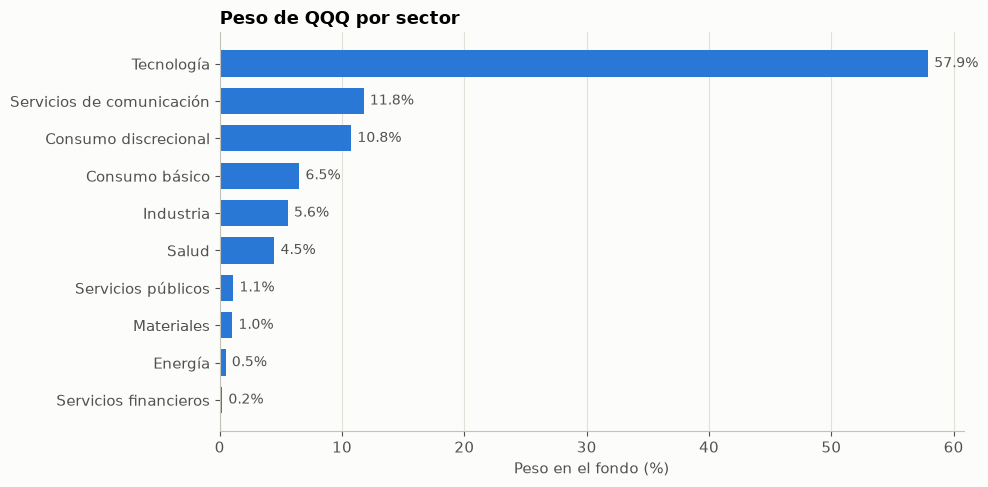

In [8]:
datos = por_sector.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(datos.index, datos["peso_pct"], color=AZUL, height=0.7)
for y, valor in enumerate(datos["peso_pct"]):
    ax.text(valor + 0.5, y, f"{valor:.1f}%", va="center", color=TEXTO, fontsize=10)
ax.set_xlabel("Peso en el fondo (%)")
ax.set_title(f"Peso de {TICKER} por sector", loc="left")
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [9]:
por_industria = (
    holdings.groupby(["sector_es", "industria"])["peso_pct"]
    .agg(["sum", "count"])
    .sort_values("sum", ascending=False)
    .head(15)
)
por_industria.columns = ["peso_pct", "num_empresas"]
print("Las 15 industrias con más peso:")
display(por_industria.round(2))

por_pais = holdings.groupby("pais")["peso_pct"].agg(["sum", "count"]).sort_values("sum", ascending=False)
por_pais.columns = ["peso_pct", "num_empresas"]
print("Sede de las empresas por país:")
display(por_pais.round(2))

Las 15 industrias con más peso:


peso_pct  \
sector_es                 industria                                       
Tecnología                Semiconductors                          25.57   
                          Software - Infrastructure               11.76   
Servicios de comunicación Internet Content & Information           8.99   
Tecnología                Consumer Electronics                     8.08   
Consumo discrecional      Internet Retail                          5.21   
Consumo básico            Discount Stores                          4.52   
Tecnología                Semiconductor Equipment & Materials      4.29   
                          Software - Application                   4.09   
Industria                 Aerospace & Defense                      3.30   
Consumo discrecional      Auto Manufacturers                       3.11   
Tecnología                Communication Equipment                  2.15   
                          Computer Hardware                        1.97   
Salud                     Drug Manufacturers - General             1.89   
Consumo básico            Beverages - Non-Alcoholic                1.63   
Salud                     Biotechnology                            1.42   

                                                               num_empresas  
sector_es                 industria                                          
Tecnología                Semiconductors                                 14  
                          Software - Infrastructure                       7  
Servicios de comunicación Internet Content & Information                  4  
Tecnología                Consumer Electronics                            1  
Consumo discrecional      Internet Retail                                 4  
Consumo básico            Discount Stores                                 2  
Tecnología                Semiconductor Equipment & Materials             5  
                          Software - Application                         11  
Industria                 Aerospace & Defense                             4  
Consumo discrecional      Auto Manufacturers                              1  
Tecnología                Communication Equipment                         2  
                          Computer Hardware                               3  
Salud                     Drug Manufacturers - General                    2  
Consumo básico            Beverages - Non-Alcoholic                       4  
Salud                     Biotechnology                                   4

Sede de las empresas por país:


,peso_pct,num_empresas
pais,,
United States,94.58,89
United Kingdom,1.64,3
Netherlands,1.24,4
Canada,1.10,2
Singapore,0.63,1
Uruguay,0.40,1
Ireland,0.23,1


### 1.4 Verificación cruzada con Yahoo Finance
Comparamos los pesos de Invesco (fuente oficial) con los que publica Yahoo Finance. **Las diferencias son normales**: Yahoo actualiza con días o semanas de retraso, y los pesos cambian todos los días porque cambian los precios de las acciones. Lo importante es que coincidan las empresas y el orden de magnitud.

In [10]:
fondo = yf.Ticker(TICKER).funds_data

top_yahoo = fondo.top_holdings["Holding Percent"].mul(100).rename("peso_yahoo_pct")
comparacion = (
    holdings.set_index("ticker")[["empresa", "peso_pct"]]
    .rename(columns={"peso_pct": "peso_invesco_pct"})
    .join(top_yahoo, how="inner")
)
comparacion["diferencia_pct"] = comparacion["peso_invesco_pct"] - comparacion["peso_yahoo_pct"]
print("Top 10 de Yahoo Finance comparado con Invesco:")
display(comparacion.round(2))

sectores_yahoo = (
    pd.Series(fondo.sector_weightings).mul(100)
    .rename(index=lambda s: SECTORES_ES.get(s.replace("_", " ").title().replace("Realestate", "Real Estate"), s))
)
comparacion_sectores = pd.DataFrame({
    "peso_invesco_pct": por_sector["peso_pct"],
    "peso_yahoo_pct": sectores_yahoo,
}).fillna(0).sort_values("peso_invesco_pct", ascending=False)
print("Peso por sector (Invesco + sector de cada empresa vs. dato agregado de Yahoo):")
display(comparacion_sectores.round(2))

Top 10 de Yahoo Finance comparado con Invesco:


,empresa,peso_invesco_pct,peso_yahoo_pct,diferencia_pct
ticker,,,,
NVDA,NVIDIA Corp,8.10,8.33,-0.23
AAPL,Apple Inc,8.08,7.35,0.73
MSFT,Microsoft Corp,6.20,5.76,0.44
MU,Micron Technology Inc,4.36,5.02,-0.66
AMZN,Amazon.com Inc,4.26,4.07,0.19
AMD,Advanced Micro Devices Inc,3.71,4.17,-0.46
TSLA,Tesla Inc,3.11,2.82,0.29
META,Meta Platforms Inc,3.04,3.26,-0.22
GOOGL,Alphabet Inc,2.99,3.05,-0.06


Peso por sector (Invesco + sector de cada empresa vs. dato agregado de Yahoo):


,peso_invesco_pct,peso_yahoo_pct
Tecnología,57.91,60.33
Servicios de comunicación,11.77,12.59
Consumo discrecional,10.75,10.07
Consumo básico,6.51,5.56
Industria,5.57,5.11
Salud,4.47,3.79
Servicios públicos,1.11,1.01
Materiales,1.03,0.92
Energía,0.49,0.45
Servicios financieros,0.21,0.19


### 1.5 Datos generales del fondo
Estos datos salen de Yahoo Finance. **Compáralos con la página de Invesco** (invesco.com/qqq-etf) antes de citarlos en el informe.

- **Gasto anual (expense ratio)**: porcentaje que el fondo cobra cada año sobre lo invertido. Es un **costo que reduce la rentabilidad** y entra en los cálculos de ingeniería económica.
- **Activos totales (AUM)**: tamaño del fondo. Un fondo grande es más estable y fácil de comprar y vender.
- **Rendimiento por dividendos**: lo que paga en dividendos al año, como % del precio.
- **Beta a 3 años**: cuánto se mueve frente al mercado (S&P 500). Beta 1.2 significa que, en promedio, si el mercado sube o baja 1%, QQQ sube o baja ~1.2%.
- **Volumen promedio**: acciones negociadas por día (liquidez).

In [11]:
info = yf.Ticker(TICKER).info
datos_fondo = pd.Series({
    "Nombre": info.get("longName"),
    "Administrador": info.get("fundFamily"),
    "Fecha de creación": pd.to_datetime(info.get("fundInceptionDate"), unit="s").date() if info.get("fundInceptionDate") else None,
    "Precio actual (USD)": info.get("previousClose"),
    "Gasto anual (%)": info.get("netExpenseRatio"),
    "Activos totales (miles de millones USD)": round(info["totalAssets"] / 1e9, 1) if info.get("totalAssets") else None,
    "Rendimiento por dividendos (%)": info.get("dividendYield"),
    "Beta a 3 años": info.get("beta3Year"),
    "Volumen promedio diario (acciones)": info.get("averageVolume"),
}, name="valor")
display(datos_fondo.to_frame())

,valor
Nombre,Invesco QQQ Trust
Administrador,Invesco
Fecha de creación,1999-03-10
Precio actual (USD),715.34
Gasto anual (%),0.18
Activos totales (miles de millones USD),498.9
Rendimiento por dividendos (%),0.42
Beta a 3 años,1.2
Volumen promedio diario (acciones),35113323


### 1.6 Conclusiones de la composición
Datos de Invesco al 23 de octubre de 2026.

1. **El fondo está muy concentrado.** Tiene 100 empresas (101 tickers, porque Alphabet tiene dos clases de acción), pero las **10 más grandes suman el 49.4%** y con **11 empresas ya se pasa del 50%**. NVIDIA (8.10%) y Apple (8.08%) solas son el 16%. En la práctica, QQQ sube o baja según lo que pase con unas pocas empresas gigantes.
2. **Es un fondo de tecnología.** El sector tecnología pesa **57.9%**, y si se suman servicios de comunicación (Alphabet, Meta) y consumo discrecional (Amazon, Tesla), casi el 80% del fondo es tecnología o empresas que dependen de ella.
3. **Los chips son el corazón del fondo.** Solo la industria de **semiconductores pesa 25.6%** (14 empresas: NVIDIA, Micron, AMD, Broadcom, Intel…), y los **equipos para fabricar chips** suman otro 4.3%. Cerca del 30% del fondo depende directamente de la cadena de suministro de chips, que se analiza en la parte 3.
4. **Casi no hay bancos.** Las reglas del Nasdaq-100 excluyen a las empresas financieras; el 0.21% de "servicios financieros" es PayPal, que Yahoo clasifica así aunque el índice la considera tecnología.
5. **Empresas de EE.UU., negocio global.** El 94.6% del peso son empresas con sede en EE.UU., pero venden en todo el mundo y fabrican en Asia (por ejemplo, TSMC en Taiwán fabrica los chips de NVIDIA, AMD y Apple, aunque TSMC no está dentro del fondo).
6. **Costo y dividendos.** El gasto anual es de **0.18%** (por cada USD 10.000 invertidos, el fondo cobra unos USD 18 al año). Los dividendos son bajos (**0.42%**), así que casi toda la ganancia viene de que suba el precio, no de pagos periódicos.
7. **Más riesgo que el mercado.** La beta de **1.2** indica que QQQ se mueve, en promedio, un 20% más que el S&P 500, tanto al subir como al bajar.
8. **La verificación cuadra.** Yahoo Finance muestra las mismas 10 empresas principales, con diferencias menores a 1 punto porcentual que se explican porque sus datos son de otra fecha.

## 2. Pronóstico con varios modelos predictivos

**Pregunta:** si hoy compro QQQ, ¿cuánto rendirá **la próxima semana** (mismo día de la semana siguiente), en los próximos **3 meses** (horizonte principal) y en los próximos **12 meses**?

### 2.1 Los 5 modelos y por qué se eligieron
| Modelo | Idea en una frase | Por qué está aquí |
|---|---|---|
| **Ingenuo (promedio histórico)** | "En el futuro rendirá lo mismo que ha rendido en promedio" | Es la **vara de medir**: un modelo que no le gane a esto no aporta nada. |
| **Regresión lineal (Ridge)** | Una suma ponderada de las variables: retorno = a·volatilidad + b·tendencia + … | Es el más simple e **interpretable**: los coeficientes dicen qué variable empuja el retorno hacia arriba o abajo. |
| **ARIMA** | Usa solo la propia historia de retornos para proyectar hacia adelante | Es el modelo **clásico de series de tiempo** de la teoría estadística y econométrica. |
| **Random Forest** | Cientos de árboles de decisión ("si la volatilidad > X y la tendencia < Y, entonces…") que votan | Captura relaciones **no lineales** y es robusto. |
| **Gradient Boosting** | Árboles en cadena: cada uno corrige los errores del anterior | Suele ser el **más preciso** en datos tabulares. |

**Variables de entrada** (lo que el modelo sabe el día que decide; todas usan solo información pasada):
- **Retornos pasados** de 5, 10, 21, 63 y 126 días: la tendencia reciente (*momentum*).
- **Volatilidad de 21 días**: qué tan nervioso está el mercado.
- **Ratio de volumen**: volumen de hoy frente al promedio del último mes (actividad inusual).
- **Ratio contra las medias móviles de 50 y 200 días**: si el precio está por encima (>1) o por debajo (<1) de su tendencia.

In [12]:
import warnings

import matplotlib.dates as mdates
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")  # aviso interno de scikit-learn al entrenar en paralelo

AÑOS_HISTORIAL = 10
HORIZONTES = {"1 semana": 5, "3 meses": 63, "12 meses": 252}  # días de bolsa (5 por semana, 21 por mes)
FRECUENCIA_PRUEBA = {"1 semana": "W", "3 meses": "M", "12 meses": "M"}  # cada cuánto se toma una decisión en la prueba
FECHA_OBJETIVO = {  # la misma fecha en calendario: mismo día de la semana siguiente, mismo día dentro de 3 o 12 meses
    "1 semana": pd.DateOffset(weeks=1),
    "3 meses": pd.DateOffset(months=3),
    "12 meses": pd.DateOffset(months=12),
}
INICIO_PRUEBA = "2022-01-01"  # la prueba incluye la caída de 2022 y la recuperación posterior

precios = yf.Ticker(TICKER).history(period=f"{AÑOS_HISTORIAL}y", interval="1d", auto_adjust=True)
precios.index = precios.index.tz_localize(None)
close = precios["Close"]
volume = precios["Volume"]

X_todo = pd.DataFrame(index=close.index)
for lag in [5, 10, 21, 63, 126]:
    X_todo[f"retorno_{lag}d"] = close.pct_change(lag)
X_todo["volatilidad_21d"] = close.pct_change().rolling(21).std() * np.sqrt(252)
X_todo["ratio_volumen"] = volume / volume.rolling(21).mean()
X_todo["ratio_ema50"] = close / close.ewm(span=50).mean()
X_todo["ratio_ema200"] = close / close.ewm(span=200).mean()
X_todo = X_todo.iloc[200:].dropna()  # se descartan los primeros 200 días para que la media de 200 tenga sentido

retornos_log = np.log(close).diff().dropna()  # entrada del ARIMA

# Lo que queremos predecir: retorno desde hoy hasta dentro de h días
objetivos = {nombre: close.shift(-h) / close - 1 for nombre, h in HORIZONTES.items()}

print(f"Datos de {TICKER}: {close.index[0].date()} a {close.index[-1].date()} ({len(close)} días de bolsa)")
print(f"Filas con variables completas: {len(X_todo)}")

Datos de QQQ: 2016-10-31 a 2026-10-30 (2514 días de bolsa)
Filas con variables completas: 2314


### 2.2 Cómo se prueba de forma justa (*walk-forward*)
El error más común al probar modelos de bolsa es dejar que el modelo "vea el futuro". Para evitarlo se simula lo que haría un inversionista real:

1. Se elige una fecha de decisión, por ejemplo el último día de bolsa de marzo de 2023.
2. El modelo se entrena **solo con datos cuyo resultado ya se conocía ese día**. Si el horizonte es de 3 meses, el último ejemplo de entrenamiento es de 3 meses antes, porque su retorno se completó justo ese día. Ese **hueco** evita que el modelo se aprenda la respuesta.
3. Se hace la predicción y se guarda junto con lo que realmente pasó.
4. Se avanza y se repite, desde enero de 2022 hasta la última fecha con resultado conocido: **cada semana** para el horizonte de 1 semana y **cada mes** para 3 y 12 meses.

Así cada modelo hace unas 240 predicciones "a ciegas" a 1 semana y entre 40 y 55 a 3 y 12 meses, como si estuviera en vivo. Esta celda tarda varios minutos porque entrena los modelos de nuevo en cada fecha.

In [13]:
NOMBRES_MODELOS = ["Ingenuo (promedio)", "Regresión lineal", "ARIMA", "Random Forest", "Gradient Boosting"]


def modelos_ml():
    return {
        "Regresión lineal": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42
        ),
    }


def prediccion_arima(fecha, h):
    """ARIMA(1,0,1) sobre los retornos diarios de los últimos 5 años; suma h días proyectados."""
    serie = retornos_log.loc[:fecha].iloc[-1260:]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ajuste = ARIMA(serie.values, order=(1, 0, 1)).fit()
    return float(np.expm1(ajuste.forecast(h).sum()))


def predecir_todos(fecha, h, y):
    """Entrena con lo que se sabía en `fecha` y devuelve la predicción de cada modelo."""
    fin_entrenamiento = close.index[close.index.get_loc(fecha) - h]  # hueco de h días
    X_train = X_todo.loc[:fin_entrenamiento]
    y_train = y.loc[X_train.index]
    x_hoy = X_todo.loc[[fecha]]

    predicciones = {"Ingenuo (promedio)": y_train.mean(), "ARIMA": prediccion_arima(fecha, h)}
    for nombre, modelo in modelos_ml().items():
        predicciones[nombre] = float(modelo.fit(X_train, y_train).predict(x_hoy)[0])
    return predicciones


resultados = {}
for nombre_h, h in HORIZONTES.items():
    y = objetivos[nombre_h]
    ultima_con_resultado = close.index[-h - 1]
    candidatas = X_todo.loc[INICIO_PRUEBA:ultima_con_resultado].index
    periodos = candidatas.to_period(FRECUENCIA_PRUEBA[nombre_h])
    fechas = candidatas.to_series().groupby(periodos).last()  # último día de bolsa de cada semana o mes

    filas = []
    for fecha in fechas:
        fila = {"fecha": fecha, "Real": y.loc[fecha]}
        fila.update(predecir_todos(fecha, h, y))
        filas.append(fila)
    resultados[nombre_h] = pd.DataFrame(filas).set_index("fecha")
    print(f"Horizonte {nombre_h}: {len(filas)} predicciones a ciegas ({fechas.iloc[0].date()} a {fechas.iloc[-1].date()})")

Horizonte 1 semana: 251 predicciones a ciegas (2022-01-07 a 2026-10-23)


Horizonte 3 meses: 56 predicciones a ciegas (2022-01-31 a 2026-08-03)


Horizonte 12 meses: 46 predicciones a ciegas (2022-01-31 a 2025-10-29)


### 2.3 Comparación de los modelos
Tres métricas para cada modelo (calculadas solo sobre las predicciones a ciegas):

- **MAE** (error absoluto medio): en promedio, ¿por cuántos puntos porcentuales se equivoca? Si el MAE es 6% y el modelo dice +4%, lo realista es esperar algo entre −2% y +10%.
- **RMSE**: parecido al MAE, pero castiga más los errores grandes. Si es mucho mayor que el MAE, el modelo a veces falla por mucho.
- **Acierto de dirección**: % de veces que acertó si QQQ iba a **subir o bajar**. Ojo: como QQQ subió la mayoría de las veces, el modelo ingenuo (que siempre dice "sube") ya acierta mucho sin saber nada. Lo que hay que ver es si los demás lo superan.
- **Mejora frente al ingenuo**: cuánto menor es el MAE del modelo que el del ingenuo. Positivo = el modelo aporta; negativo = es peor que no usar modelo.

In [14]:
def tabla_metricas(res):
    filas = []
    for modelo in NOMBRES_MODELOS:
        filas.append({
            "Modelo": modelo,
            "MAE (%)": mean_absolute_error(res["Real"], res[modelo]) * 100,
            "RMSE (%)": np.sqrt(mean_squared_error(res["Real"], res[modelo])) * 100,
            "Acierto de dirección (%)": (np.sign(res[modelo]) == np.sign(res["Real"])).mean() * 100,
        })
    tabla = pd.DataFrame(filas).set_index("Modelo")
    tabla["Mejora vs. ingenuo (%)"] = (1 - tabla["MAE (%)"] / tabla.loc["Ingenuo (promedio)", "MAE (%)"]) * 100
    return tabla


metricas = {nombre_h: tabla_metricas(res) for nombre_h, res in resultados.items()}
for nombre_h, tabla in metricas.items():
    subio = (resultados[nombre_h]["Real"] > 0).mean() * 100
    print(f"\n=== Horizonte {nombre_h} ===  (QQQ subió en el {subio:.0f}% de las fechas de prueba)")
    display(tabla.round(2))


=== Horizonte 1 semana ===  (QQQ subió en el 55% de las fechas de prueba)


,MAE (%),RMSE (%),Acierto de dirección (%),Mejora vs. ingenuo (%)
Modelo,,,,
Ingenuo (promedio),2.38,3.01,54.58,0.00
Regresión lineal,2.46,3.09,52.59,-3.46
ARIMA,2.39,3.02,54.58,-0.33
Random Forest,2.37,3.00,58.57,0.28
Gradient Boosting,2.39,2.99,57.77,-0.56



=== Horizonte 3 meses ===  (QQQ subió en el 68% de las fechas de prueba)


,MAE (%),RMSE (%),Acierto de dirección (%),Mejora vs. ingenuo (%)
Modelo,,,,
Ingenuo (promedio),8.00,10.06,67.86,0.00
Regresión lineal,9.48,11.99,60.71,-18.44
ARIMA,7.90,10.09,67.86,1.26
Random Forest,9.69,12.37,55.36,-21.15
Gradient Boosting,9.48,12.21,60.71,-18.50



=== Horizonte 12 meses ===  (QQQ subió en el 93% de las fechas de prueba)


,MAE (%),RMSE (%),Acierto de dirección (%),Mejora vs. ingenuo (%)
Modelo,,,,
Ingenuo (promedio),12.46,16.83,93.48,0.00
Regresión lineal,16.31,21.12,93.48,-30.92
ARIMA,13.56,17.81,93.48,-8.84
Random Forest,16.43,20.74,82.61,-31.94
Gradient Boosting,16.86,20.35,86.96,-35.32


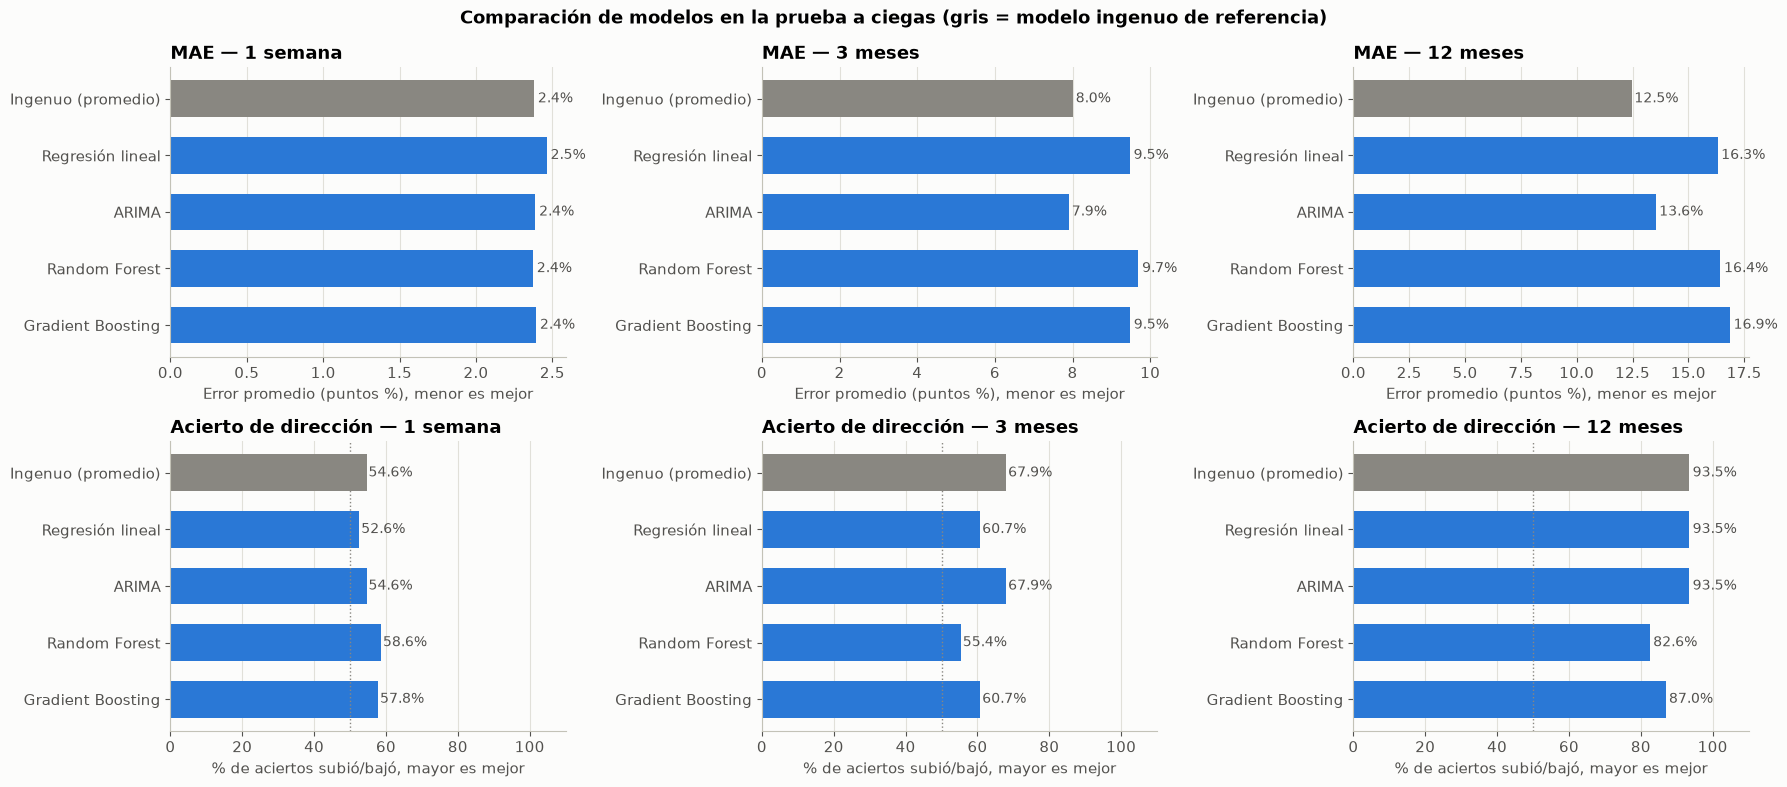

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for col, (nombre_h, tabla) in enumerate(metricas.items()):
    datos = tabla.iloc[::-1]
    colores = [GRIS if m == "Ingenuo (promedio)" else AZUL for m in datos.index]
    for fila, (metrica, sufijo) in enumerate([("MAE (%)", "%"), ("Acierto de dirección (%)", "%")]):
        ax = axes[fila, col]
        ax.barh(datos.index, datos[metrica], color=colores, height=0.65)
        for y_pos, valor in enumerate(datos[metrica]):
            ax.text(valor * 1.01, y_pos, f"{valor:.1f}{sufijo}", va="center", color=TEXTO, fontsize=10)
        if metrica.startswith("Acierto"):
            ax.axvline(50, color=GRIS, linestyle=":", linewidth=1)
            ax.set_xlim(0, 110)
        ax.set_title(f"{metrica.replace(' (%)', '')} — {nombre_h}", loc="left")
        ax.set_xlabel("Error promedio (puntos %), menor es mejor" if fila == 0 else "% de aciertos subió/bajó, mayor es mejor")
        ax.grid(axis="x")
        ax.set_axisbelow(True)
fig.suptitle("Comparación de modelos en la prueba a ciegas (gris = modelo ingenuo de referencia)", fontweight="bold")
plt.tight_layout()
plt.show()

### 2.4 Predicción contra realidad, fecha por fecha
Cada panel es un modelo. La línea **gris** es lo que realmente rindió QQQ desde esa fecha hasta el final del horizonte; la línea **azul** es lo que el modelo predijo ese día. Cuanto más se parezcan, mejor. Fíjate sobre todo en **2022**, cuando QQQ cayó fuerte: ahí se ve qué modelos anticipan las caídas y cuáles no.

In [16]:
def grafica_real_vs_prediccion(nombre_h):
    res = resultados[nombre_h] * 100
    fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey=True)
    axes = axes.flatten()
    for ax, modelo in zip(axes, NOMBRES_MODELOS):
        ax.axhline(0, color="#c3c2b7", linewidth=1)
        ax.plot(res.index, res["Real"], color=GRIS, linewidth=2, label="Retorno real")
        ax.plot(res.index, res[modelo], color=AZUL, linewidth=2, label="Predicción")
        mae = metricas[nombre_h].loc[modelo, "MAE (%)"]
        ax.set_title(f"{modelo} (MAE {mae:.1f}%)", loc="left")
        ax.grid(True)
        ax.set_axisbelow(True)
    axes[-1].axis("off")
    axes[3].tick_params(labelbottom=True)  # el panel vacío deja sin fechas a la columna derecha
    axes[0].xaxis.set_major_locator(mdates.YearLocator())
    axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[0].legend(loc="upper left", frameon=False)
    for ax in axes[::2]:
        ax.set_ylabel("Retorno (%)")
    fig.suptitle(f"{TICKER}: retorno real vs. predicho a {nombre_h} (cada punto = una fecha de decisión)", fontweight="bold")
    plt.tight_layout()
    plt.show()

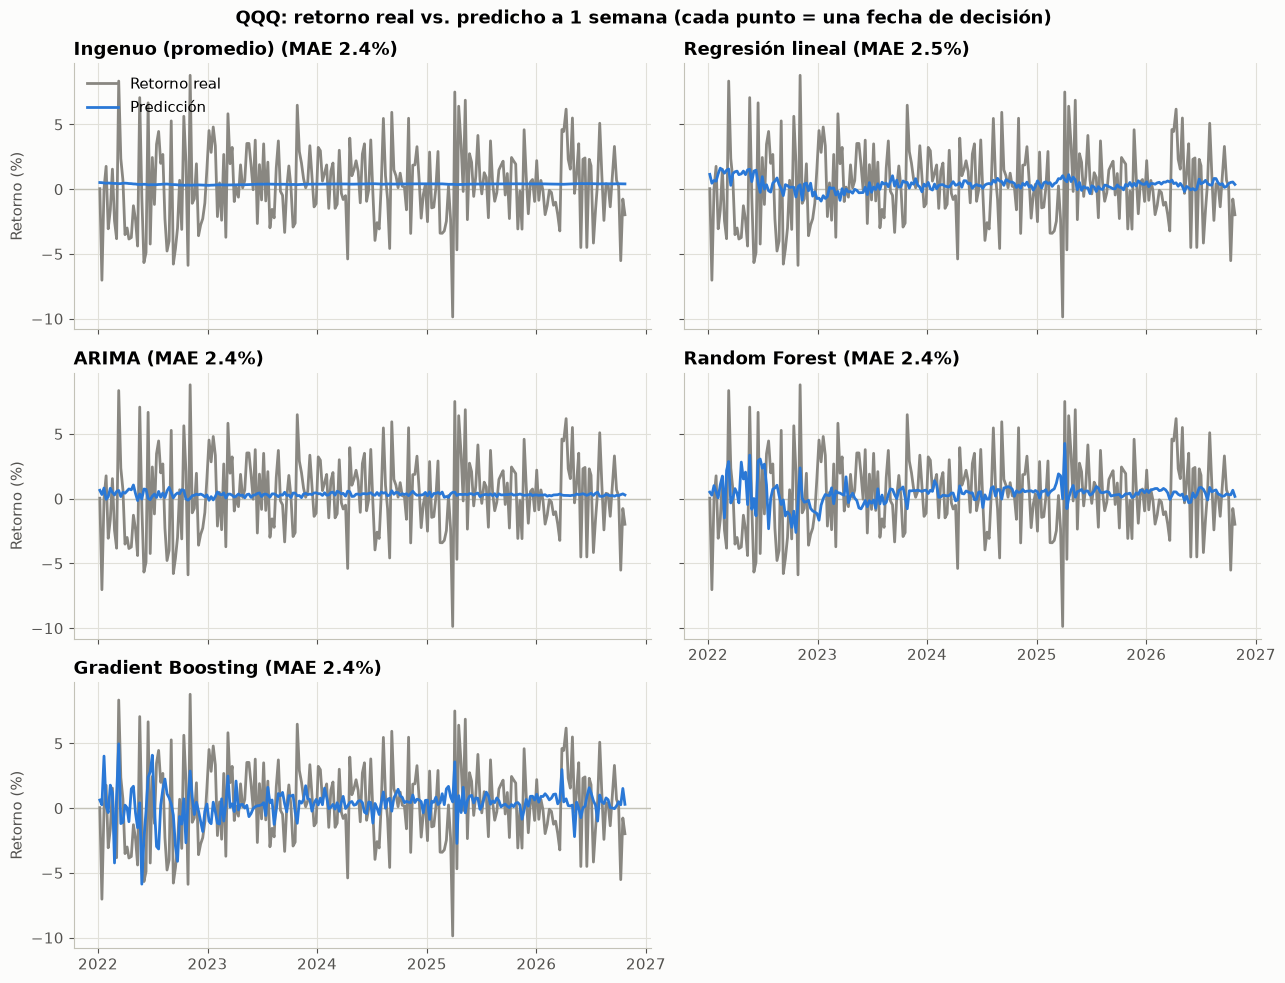

In [17]:
grafica_real_vs_prediccion("1 semana")

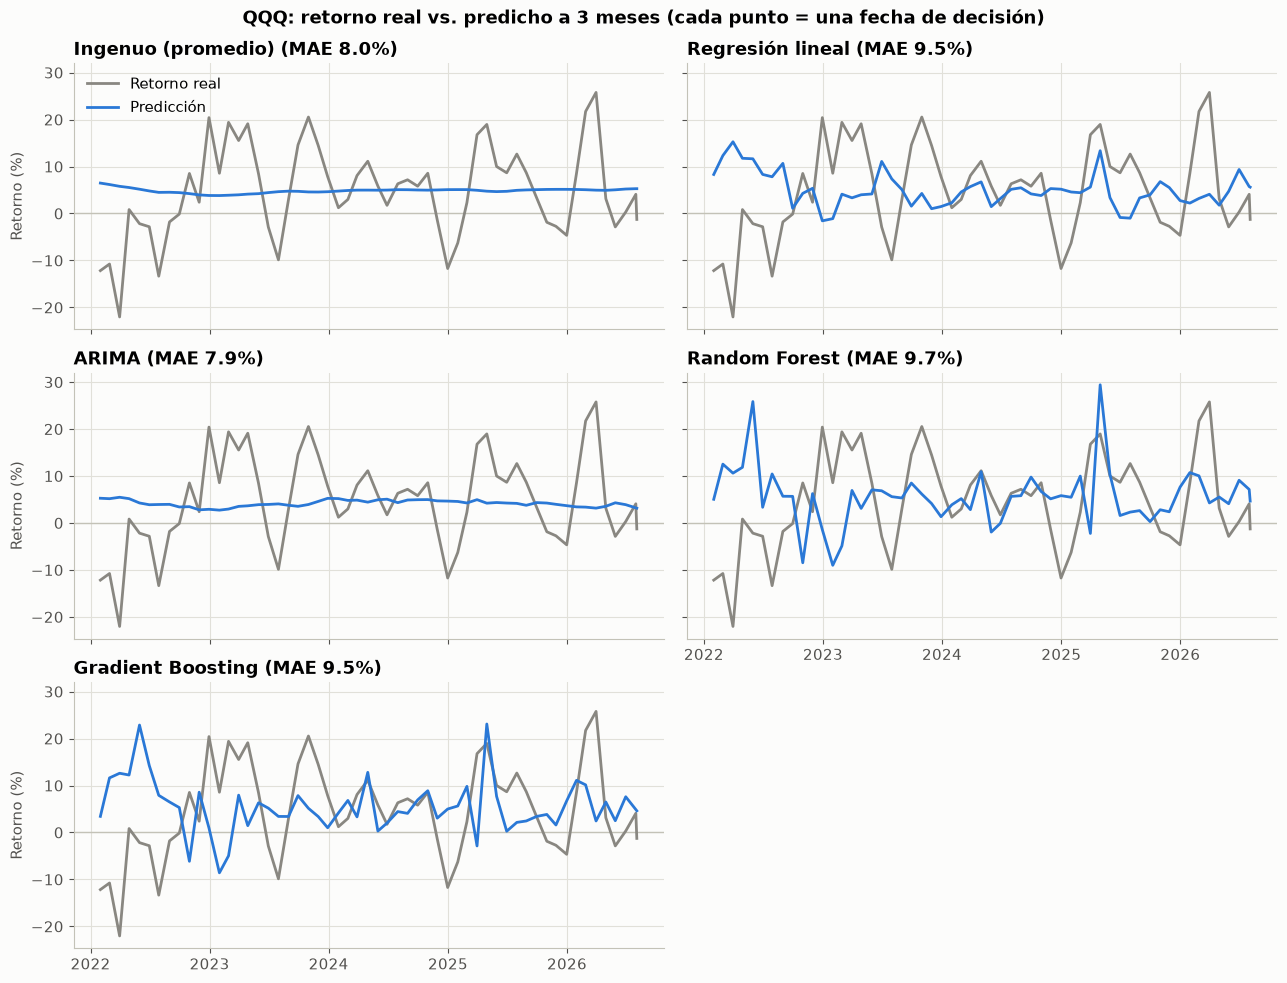

In [18]:
grafica_real_vs_prediccion("3 meses")

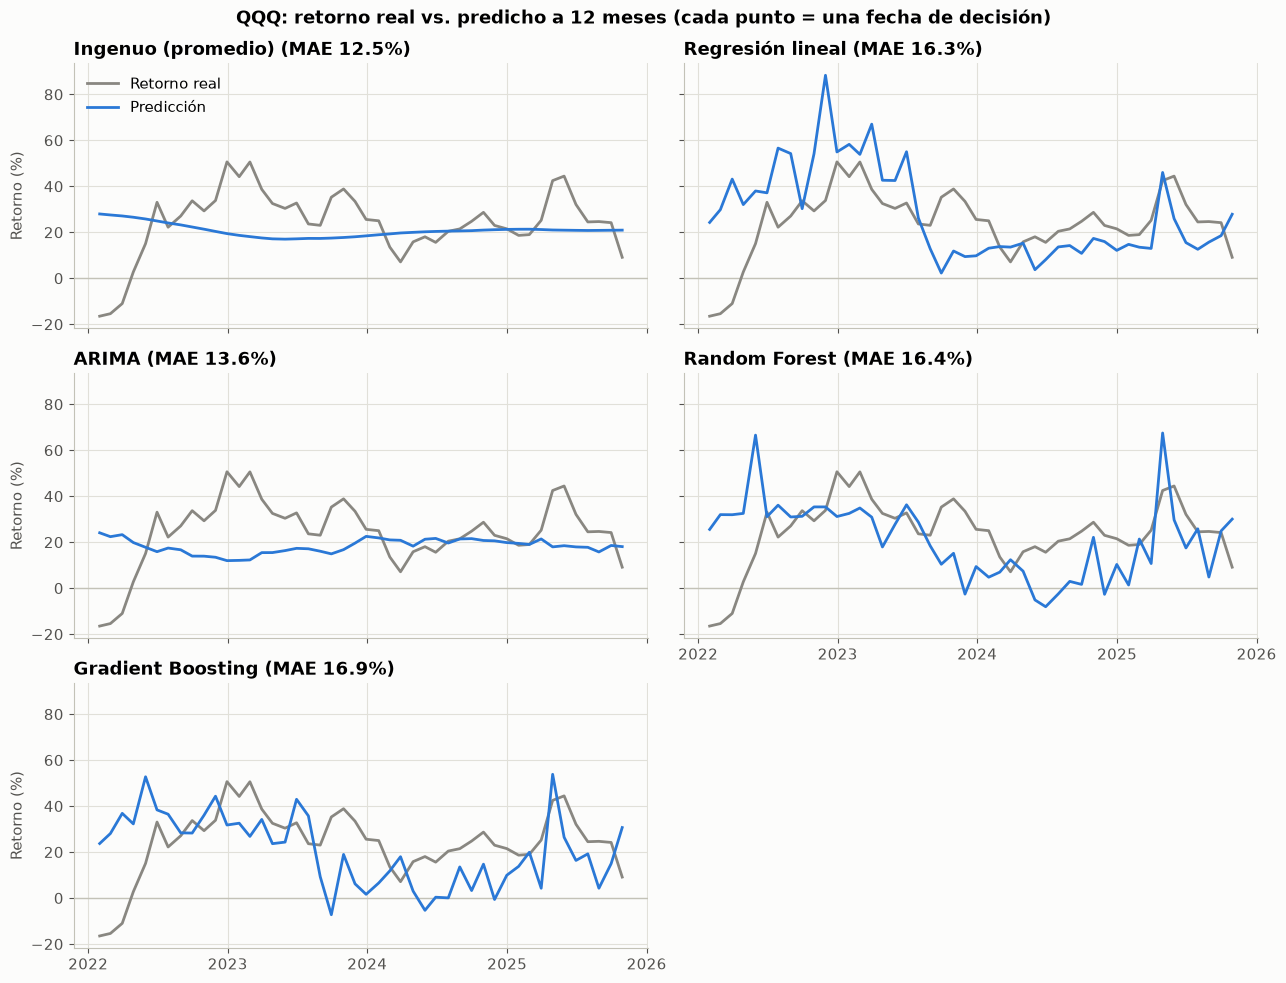

In [19]:
grafica_real_vs_prediccion("12 meses")

### 2.5 ¿Qué variables usan más los modelos?
El Random Forest permite medir cuánto **usa** cada variable para decidir (*importancia*). Esto no prueba causalidad, pero indica qué señales del mercado tienen más relación con el retorno futuro, y conecta con el análisis de causa y efecto de la parte 3.

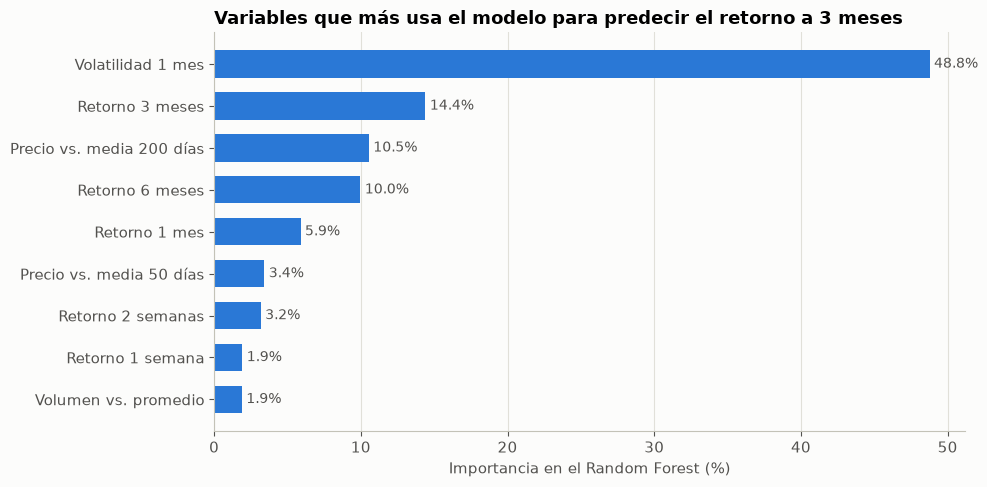

In [20]:
NOMBRES_VARIABLES = {
    "retorno_5d": "Retorno 1 semana",
    "retorno_10d": "Retorno 2 semanas",
    "retorno_21d": "Retorno 1 mes",
    "retorno_63d": "Retorno 3 meses",
    "retorno_126d": "Retorno 6 meses",
    "volatilidad_21d": "Volatilidad 1 mes",
    "ratio_volumen": "Volumen vs. promedio",
    "ratio_ema50": "Precio vs. media 50 días",
    "ratio_ema200": "Precio vs. media 200 días",
}

y_3m = objetivos["3 meses"].loc[X_todo.index].dropna()
bosque = modelos_ml()["Random Forest"].fit(X_todo.loc[y_3m.index], y_3m)
importancia = (
    pd.Series(bosque.feature_importances_, index=X_todo.columns)
    .rename(index=NOMBRES_VARIABLES)
    .sort_values()
    * 100
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(importancia.index, importancia.values, color=AZUL, height=0.65)
for y_pos, valor in enumerate(importancia.values):
    ax.text(valor + 0.3, y_pos, f"{valor:.1f}%", va="center", color=TEXTO, fontsize=10)
ax.set_xlabel("Importancia en el Random Forest (%)")
ax.set_title("Variables que más usa el modelo para predecir el retorno a 3 meses", loc="left")
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### 2.6 Pronóstico de hoy
Ahora cada modelo se entrena con **toda** la historia conocida y predice desde el último día disponible. La columna **rango probable** suma y resta el MAE de la prueba a ciegas: es la forma honesta de leer un pronóstico, porque el número puntual casi nunca se cumple exacto.

In [21]:
fecha_hoy = X_todo.index[-1]
x_hoy = X_todo.loc[[fecha_hoy]]
precio_hoy = close.loc[fecha_hoy]

filas = []
for nombre_h, h in HORIZONTES.items():
    y = objetivos[nombre_h].loc[X_todo.index].dropna()
    X_train = X_todo.loc[y.index]
    predicciones = {"Ingenuo (promedio)": y.mean(), "ARIMA": prediccion_arima(fecha_hoy, h)}
    for nombre, modelo in modelos_ml().items():
        predicciones[nombre] = float(modelo.fit(X_train, y).predict(x_hoy)[0])
    for modelo in NOMBRES_MODELOS:
        p = predicciones[modelo] * 100
        mae = metricas[nombre_h].loc[modelo, "MAE (%)"]
        filas.append({
            "Horizonte": nombre_h,
            "Fecha objetivo": (fecha_hoy + FECHA_OBJETIVO[nombre_h]).date(),
            "Modelo": modelo,
            "Retorno esperado (%)": round(p, 2),
            "Rango probable (%)": f"{p - mae:.1f} a {p + mae:.1f}",
            "Precio esperado (USD)": round(precio_hoy * (1 + p / 100), 2),
        })

pronostico = pd.DataFrame(filas).set_index(["Horizonte", "Fecha objetivo", "Modelo"])
print(f"Precio de {TICKER} al {fecha_hoy.date()}: USD {precio_hoy:.2f}")
display(pronostico)

Precio de QQQ al 2026-10-30: USD 690.49


Retorno esperado (%)  \
Horizonte Fecha objetivo Modelo                                     
1 semana  2026-11-06     Ingenuo (promedio)                  0.41   
                         Regresión lineal                    0.33   
                         ARIMA                               0.45   
                         Random Forest                       0.73   
                         Gradient Boosting                   0.11   
3 meses   2027-01-30     Ingenuo (promedio)                  5.19   
                         Regresión lineal                    4.80   
                         ARIMA                               3.46   
                         Random Forest                       7.82   
                         Gradient Boosting                   7.76   
12 meses  2027-10-30     Ingenuo (promedio)                 21.60   
                         Regresión lineal                   11.67   
                         ARIMA                              13.88   
                         Random Forest                      22.14   
                         Gradient Boosting                  23.45   

                                            Rango probable (%)  \
Horizonte Fecha objetivo Modelo                                  
1 semana  2026-11-06     Ingenuo (promedio)         -2.0 a 2.8   
                         Regresión lineal           -2.1 a 2.8   
                         ARIMA                      -1.9 a 2.8   
                         Random Forest              -1.6 a 3.1   
                         Gradient Boosting          -2.3 a 2.5   
3 meses   2027-01-30     Ingenuo (promedio)        -2.8 a 13.2   
                         Regresión lineal          -4.7 a 14.3   
                         ARIMA                     -4.4 a 11.4   
                         Random Forest             -1.9 a 17.5   
                         Gradient Boosting         -1.7 a 17.2   
12 meses  2027-10-30     Ingenuo (promedio)         9.1 a 34.1   
                         Regresión lineal          -4.6 a 28.0   
                         ARIMA                      0.3 a 27.4   
                         Random Forest              5.7 a 38.6   
                         Gradient Boosting          6.6 a 40.3   

                                             Precio esperado (USD)  
Horizonte Fecha objetivo Modelo                                     
1 semana  2026-11-06     Ingenuo (promedio)                 693.31  
                         Regresión lineal                   692.78  
                         ARIMA                              693.60  
                         Random Forest                      695.51  
                         Gradient Boosting                  691.23  
3 meses   2027-01-30     Ingenuo (promedio)                 726.29  
                         Regresión lineal                   723.63  
                         ARIMA                              714.35  
                         Random Forest                      744.51  
                         Gradient Boosting                  744.09  
12 meses  2027-10-30     Ingenuo (promedio)                 839.67  
                         Regresión lineal                   771.04  
                         ARIMA                              786.35  
                         Random Forest                      843.34  
                         Gradient Boosting                  852.43

### 2.7 Registro semanal: ¿acertó el pronóstico de la semana pasada?
Cada vez que se corre el notebook, el pronóstico de hoy se **guarda** en `datos/registro_pronosticos.csv`. La semana siguiente, cuando ya se conoce el precio real de la fecha objetivo, la tabla de abajo muestra cuánto se equivocó cada modelo. Si la fecha objetivo cae en festivo, se usa el último cierre anterior.

Correrlo cada semana en clase permite ir armando un historial propio de aciertos y errores.

In [22]:
REGISTRO_CSV = Path("datos/registro_pronosticos.csv")

nuevos = (
    pronostico.reset_index()
    .assign(fecha_dato=fecha_hoy.date(), precio_base=round(precio_hoy, 2))
    [["fecha_dato", "Horizonte", "Fecha objetivo", "Modelo", "precio_base", "Retorno esperado (%)", "Precio esperado (USD)"]]
)
if REGISTRO_CSV.exists():
    registro = pd.concat([pd.read_csv(REGISTRO_CSV), nuevos])
else:
    registro = nuevos
registro["fecha_dato"] = pd.to_datetime(registro["fecha_dato"])
registro["Fecha objetivo"] = pd.to_datetime(registro["Fecha objetivo"])
registro = registro.drop_duplicates(["fecha_dato", "Horizonte", "Modelo"], keep="last")  # correr dos veces el mismo día no duplica
registro.to_csv(REGISTRO_CSV, index=False)
print(f"Pronósticos guardados en {REGISTRO_CSV} ({len(registro)} filas en total)")

vencidos = registro[registro["Fecha objetivo"] <= close.index[-1]].copy()
if vencidos.empty:
    print(f"Todavía no hay pronósticos con fecha objetivo cumplida. El primero vence el {registro['Fecha objetivo'].min().date()}.")
else:
    vencidos["Precio real (USD)"] = close.asof(vencidos["Fecha objetivo"]).values.round(2)
    vencidos["Retorno real (%)"] = ((vencidos["Precio real (USD)"] / vencidos["precio_base"] - 1) * 100).round(2)
    vencidos["Error (puntos %)"] = (vencidos["Retorno esperado (%)"] - vencidos["Retorno real (%)"]).round(2)
    vencidos["¿Acertó la dirección?"] = (vencidos["Retorno esperado (%)"] > 0) == (vencidos["Retorno real (%)"] > 0)
    display(vencidos.set_index(["fecha_dato", "Horizonte", "Modelo"]))

Pronósticos guardados en datos\registro_pronosticos.csv (30 filas en total)


Fecha objetivo  precio_base  \
fecha_dato Horizonte Modelo                                           
2026-10-23 1 semana  Ingenuo (promedio)     2026-10-30        704.4   
                     Regresión lineal       2026-10-30        704.4   
                     ARIMA                  2026-10-30        704.4   
                     Random Forest          2026-10-30        704.4   
                     Gradient Boosting      2026-10-30        704.4   

                                         Retorno esperado (%)  \
fecha_dato Horizonte Modelo                                     
2026-10-23 1 semana  Ingenuo (promedio)                  0.41   
                     Regresión lineal                    0.37   
                     ARIMA                               0.29   
                     Random Forest                       0.34   
                     Gradient Boosting                   0.21   

                                         Precio esperado (USD)  \
fecha_dato Horizonte Modelo                                      
2026-10-23 1 semana  Ingenuo (promedio)                 707.26   
                     Regresión lineal                   706.97   
                     ARIMA                              706.42   
                     Random Forest                      706.79   
                     Gradient Boosting                  705.87   

                                         Precio real (USD)  Retorno real (%)  \
fecha_dato Horizonte Modelo                                                    
2026-10-23 1 semana  Ingenuo (promedio)             690.49             -1.97   
                     Regresión lineal               690.49             -1.97   
                     ARIMA                          690.49             -1.97   
                     Random Forest                  690.49             -1.97   
                     Gradient Boosting              690.49             -1.97   

                                         Error (puntos %)  \
fecha_dato Horizonte Modelo                                 
2026-10-23 1 semana  Ingenuo (promedio)              2.38   
                     Regresión lineal                2.34   
                     ARIMA                           2.26   
                     Random Forest                   2.31   
                     Gradient Boosting               2.18   

                                         ¿Acertó la dirección?  
fecha_dato Horizonte Modelo                                     
2026-10-23 1 semana  Ingenuo (promedio)                  False  
                     Regresión lineal                    False  
                     ARIMA                               False  
                     Random Forest                       False  
                     Gradient Boosting                   False

### 2.8 Conclusiones de los modelos
1. **Ningún modelo de machine learning le ganó al modelo ingenuo.** A 3 meses, el ingenuo se equivoca en promedio 8.0 puntos; ARIMA prácticamente empata (7.95, apenas 1% mejor), y la regresión lineal, el Random Forest y el Gradient Boosting son **entre 18% y 21% peores**. A 12 meses todos son peores que el ingenuo.
2. **A 1 semana todos quedan prácticamente empatados** (error promedio de ~2.4 puntos). El Random Forest y el Gradient Boosting acertaron la dirección el 59% de las semanas frente al 55% del ingenuo, pero con 251 semanas de prueba el margen de error de ese porcentaje es de unos ±6 puntos, así que la ventaja todavía puede ser suerte. El registro semanal (2.7) sirve justamente para seguir comprobándolo.
3. **Esto es un resultado esperado, no un error del código.** Coincide con la **hipótesis de mercados eficientes** (en su forma débil): los precios pasados ya reflejan la información disponible, así que los patrones históricos de precio y volumen casi no sirven para anticipar el futuro. Además, los modelos complejos se **sobreajustan**: aprenden "patrones" de 2016-2021 que eran ruido y no se repitieron en 2022-2026. En las gráficas se ve: el Random Forest y el Gradient Boosting dan saltos (predicen +25%) que luego no ocurren.
4. **El ingenuo y ARIMA predicen casi una línea plana** de +4% a +6% cada 3 meses, que es la tendencia promedio de largo plazo de QQQ. Por eso **ninguno anticipa las caídas** (2022, comienzos de 2025): las caídas fuertes llegan por noticias y eventos que no están en los precios pasados (ver parte 3).
5. **Cuidado con el acierto de dirección.** El ingenuo acierta 68% a 3 meses solo porque QQQ subió en el 68% de las fechas (y 93% a 12 meses). Los modelos complejos bajan a 55%-61%: cuando intentan adivinar las caídas, fallan más de lo que aciertan.
6. **La incertidumbre es grande.** Un error promedio de 8 puntos frente a un retorno esperado de ~5% a 3 meses significa que el resultado realista va desde una pérdida hasta una ganancia de dos dígitos. Para la decisión de inversión importa más el **rango** que el número puntual.
7. **La volatilidad es la señal más usada** por el Random Forest (48% de importancia): los periodos de mercado nervioso son los que traen los movimientos grandes, en ambas direcciones. Esto conecta con las causas externas de la parte 3 (tasas de interés, aranceles, resultados de las grandes tecnológicas).
8. **Pronóstico de hoy:** con el cierre del 30 de octubre de 2026 (USD 690.49), para la **próxima semana** los modelos esperan entre **−0.3% y +0.7%** (un rango realista de −3% a +3%), entre **+3.5% y +7.8% a 3 meses** y entre **+12% y +25% a 12 meses**, pero con rangos amplios (las cifras exactas pueden variar en decimales cada vez que se corre, porque Yahoo ajusta levemente los precios históricos). El +21.6% a 12 meses del ingenuo refleja una década excepcional para la tecnología y no es garantía de que se repita.
9. **Primer pronóstico verificado.** El 23 de octubre todos los modelos esperaban que QQQ subiera entre +0.2% y +0.4% en la semana; en realidad **cayó −1.97%** (de USD 704.40 a USD 690.49). Los cinco fallaron la dirección, con errores de 2.2 a 2.4 puntos, justo del tamaño del MAE de la prueba a ciegas (~2.4). El rango probable sí contenía el resultado: es exactamente lo que se esperaba de la parte 2.3.
10. **Conclusión práctica:** los modelos sirven como **referencia de rango y de riesgo**, no como señal de compra o venta. La decisión de invertir en QQQ debe basarse en el horizonte (a más plazo, más probabilidad histórica de ganar), la tolerancia a caídas de 20%-35% y los costos.

## 3. Cadena de suministro y relación causa-efecto

La parte 1 mostró que QQQ es, sobre todo, un fondo de tecnología, y que los chips son su corazón. Para entender **por qué sube o baja**, hay que ver cómo se conectan sus empresas: casi todas forman parte de una misma cadena, que va del silicio hasta el cliente final.

![Cadena de suministro de QQQ](https://raw.githubusercontent.com/Chaparroo/analisis-qqq-ingenieria-economica-/master/informe/cadena_suministro_qqq.png)

**Cómo leer el diagrama**
- Cada **caja azul** es un eslabón de la cadena con las empresas de QQQ que lo forman y cuánto pesan en el fondo.
- Las **cajas grises** son actores clave que **no están dentro del fondo** pero de los que dependen todos (por ejemplo TSMC, en Taiwán, fabrica los chips de NVIDIA, AMD y Apple).
- Las **flechas grises** muestran cómo viajan los productos; la **flecha azul punteada** muestra que el **dinero y la demanda viajan al revés**: los clientes pagan a la nube y a los fabricantes de dispositivos, que compran chips, que necesitan fábricas y máquinas.
- Los **círculos naranjas** indican qué causa externa golpea primero a cada eslabón (leyenda abajo de la imagen).

Los pesos de cada eslabón en el diagrama salen del archivo oficial de Invesco del 23 de octubre de 2026.

### 3.1 Cómo se transmite un efecto a lo largo de la cadena
Como los eslabones dependen unos de otros, una noticia que golpea a uno se **contagia** a los demás. Y como las empresas de la cadena suman cerca del **70% del fondo**, el efecto llega al precio de QQQ.

**Ejemplo de subida: más inversión en inteligencia artificial**
1. Microsoft, Amazon, Google y Meta anuncian que gastarán más en centros de datos (*causa 2*).
2. Le compran más procesadores a **NVIDIA, AMD y Broadcom** y más memoria a **Micron**.
3. Esas empresas le encargan más producción a **TSMC**.
4. TSMC necesita más máquinas: compra a **ASML, Applied Materials, Lam Research y KLA**.
5. Los centros de datos necesitan más electricidad: se benefician **Constellation Energy** y otras eléctricas.
6. Suben las ganancias esperadas de casi toda la cadena, suben sus acciones y **QQQ sube**.

**Ejemplo de bajada: restricciones de exportación a China**
1. EE.UU. prohíbe vender ciertos chips o máquinas a China (*causa 3*).
2. **NVIDIA y AMD** pierden un mercado grande; **ASML, Lam y Applied Materials** también, porque China es uno de sus mayores compradores de máquinas.
3. Bajan las ganancias esperadas de esas empresas y caen sus acciones.
4. Como pesan mucho en el fondo, **QQQ cae**, aunque el resto de la economía esté bien.

### 3.2 Por qué las tasas de interés mueven a todo el fondo (conexión con ingeniería económica)
El precio de una acción es, en teoría, el **valor presente** de todas las ganancias que la empresa generará en el futuro:

$$P = \sum_{t=1}^{n} \frac{FC_t}{(1+i)^t}$$

donde $FC_t$ es el flujo de caja del año $t$ e $i$ es la **tasa de descuento**, que depende de las tasas de interés.

Las empresas de QQQ son de **crecimiento**: buena parte de sus ganancias está lejos en el futuro (*t* grande). Cuanto más lejano es un flujo, más lo afecta un cambio en *i*, porque el denominador $(1+i)^t$ crece más rápido. Por eso:
- **Si la Reserva Federal sube las tasas**, el valor presente de esas ganancias futuras cae mucho y QQQ baja más que el mercado (eso pasó en 2022, cuando QQQ cayó cerca de 33%).
- **Si las tasas bajan**, ocurre lo contrario y QQQ suele subir más que el mercado.

Esto también explica la **beta de 1.2** de la parte 1: QQQ es más sensible que el S&P 500 a los cambios en las condiciones financieras.

### 3.3 Resumen de causas y efectos
| # | Causa | Eslabón que golpea primero | QQQ tiende a **subir** si… | QQQ tiende a **bajar** si… |
|---|---|---|---|---|
| 1 | Tasas de interés (Reserva Federal) | Todo el fondo | las tasas bajan o se espera que bajen | las tasas suben o la inflación sorprende al alza |
| 2 | Inversión en IA de las grandes tecnológicas | Nube → diseño de chips → memoria | anuncian más gasto en centros de datos | recortan el gasto o dudan de la rentabilidad de la IA |
| 3 | Aranceles y controles de exportación | Diseño de chips y máquinas | se relajan las restricciones | se endurecen o hay guerra comercial |
| 4 | Riesgo geopolítico en Taiwán | Fabricación y ensamble | baja la tensión | sube la tensión o hay interrupciones en TSMC |
| 5 | Ciclo de precios de la memoria | Memoria (Micron, Sandisk…) | hay escasez y los precios suben | hay exceso de oferta y los precios caen |
| 6 | Costo y disponibilidad de energía | Energía y centros de datos | hay energía suficiente y barata | la falta de energía frena la construcción de centros de datos |
| 7 | Consumo y resultados trimestrales | Dispositivos y clientes finales | los reportes superan lo esperado | los reportes decepcionan o el consumo se debilita |

### 3.4 Evidencia con datos: ¿qué eslabón movió más a QQQ en el último año?
Para comprobar que la cadena realmente explica el precio, calculamos la **contribución** de cada empresa al retorno de QQQ en los últimos 12 meses:

$$\text{contribución} = \text{peso al inicio del año} \times \text{retorno de la acción en el año}$$

Por ejemplo, si una empresa pesaba 2% hace un año y subió 50%, aportó 0.02 × 50 = 1 punto al retorno de QQQ. Sumando por eslabón se ve qué parte de la cadena empujó más.

**Detalle importante:** Invesco solo publica los pesos de hoy, y no se pueden usar directamente: una empresa que subió 300% pesa hoy mucho más que hace un año, y su aporte quedaría inflado. Por eso se **estima el peso al inicio** devolviendo cada peso a su valor de hace un año:

$$w_{inicio} \propto \frac{w_{hoy}}{1 + r}$$

El resultado es una aproximación: la suma no coincide exactamente con el retorno real de QQQ, porque durante el año el índice se rebalanceó y algunas empresas entraron o salieron.

In [23]:
# Empresas de QQQ en cada eslabón de la cadena (las mismas del diagrama)
ESLABONES = {
    "Software de diseño y arquitectura": ["SNPS", "CDNS", "ARM"],
    "Máquinas para fabricar chips": ["ASML", "AMAT", "LRCX", "KLAC", "TER"],
    "Materiales y gases": ["LIN"],
    "Diseño de chips (procesadores, IA, redes)": [
        "NVDA", "AMD", "AVGO", "INTC", "QCOM", "MRVL", "TXN", "ADI", "NXPI", "MPWR", "MCHP", "ALAB",
    ],
    "Memoria y almacenamiento": ["MU", "SNDK", "WDC", "STX"],
    "Energía para centros de datos": ["CEG", "AEP", "XEL", "EXC"],
    "Ensamble de equipos y redes": ["CSCO", "LITE"],
    "Nube e inteligencia artificial": ["MSFT", "AMZN", "GOOGL", "GOOG", "META", "CRWV", "NBIS"],
    "Dispositivos y vehículos": ["AAPL", "TSLA", "SPCX"],
}

eslabon_de = {t: titulo for titulo, tickers in ESLABONES.items() for t in tickers}
OTRAS = "Fuera de la cadena (consumo, salud, software…)"

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # avisos internos de yfinance
    precios_1a = yf.download(holdings["ticker"].tolist(), period="1y", auto_adjust=True, progress=False, threads=False)["Close"]
inicio_ventana = precios_1a.index[0]


def retorno_periodo(serie):
    serie = serie.dropna()
    return serie.iloc[-1] / serie.iloc[0] - 1 if len(serie) > 1 else np.nan


contrib = holdings[["ticker", "empresa", "peso_pct"]].copy()
contrib["eslabon"] = contrib["ticker"].map(eslabon_de).fillna(OTRAS)
contrib["retorno_1a_pct"] = contrib["ticker"].map(precios_1a.apply(retorno_periodo)) * 100
peso_sin_subida = contrib["peso_pct"] / (1 + contrib["retorno_1a_pct"] / 100)
contrib["peso_inicio_pct"] = peso_sin_subida / peso_sin_subida.sum() * contrib["peso_pct"].sum()
contrib["contribucion_pts"] = contrib["peso_inicio_pct"] * contrib["retorno_1a_pct"] / 100

nuevas = [t for t in contrib["ticker"] if precios_1a[t].first_valid_index() > inicio_ventana + pd.Timedelta(days=10)]
if nuevas:
    print(f"Empresas con menos de 1 año en bolsa (su retorno se mide desde su primer día): {', '.join(nuevas)}")

por_eslabon = (
    contrib.groupby("eslabon")
    .agg(peso_inicio_pct=("peso_inicio_pct", "sum"), peso_pct=("peso_pct", "sum"),
         contribucion_pts=("contribucion_pts", "sum"), num_empresas=("ticker", "count"))
    .sort_values("contribucion_pts", ascending=False)
)
retorno_qqq = (close.iloc[-1] / close.asof(inicio_ventana) - 1) * 100
print(f"\nRetorno real de {TICKER} en el último año: {retorno_qqq:.1f}%")
print(f"Suma de contribuciones (aproximación con pesos estimados al inicio): {contrib['contribucion_pts'].sum():.1f} puntos")
print(f"Aporte de la cadena de suministro: {por_eslabon.drop(OTRAS)['contribucion_pts'].sum():.1f} puntos "
      f"con {por_eslabon.drop(OTRAS)['peso_inicio_pct'].sum():.1f}% del peso al inicio del año")
display(por_eslabon.round(2))

Empresas con menos de 1 año en bolsa (su retorno se mide desde su primer día): SPCX, HONA

Retorno real de QQQ en el último año: 10.3%
Suma de contribuciones (aproximación con pesos estimados al inicio): 13.0 puntos
Aporte de la cadena de suministro: 12.9 puntos con 66.6% del peso al inicio del año


,peso_inicio_pct,peso_pct,contribucion_pts,num_empresas
eslabon,,,,
Memoria y almacenamiento,1.93,6.33,5.22,4
"Diseño de chips (procesadores, IA, redes)",19.10,20.81,4.43,12
Máquinas para fabricar chips,3.20,4.29,1.65,5
Ensamble de equipos y redes,1.52,2.15,0.91,2
Dispositivos y vehículos,14.91,13.97,0.88,3
Materiales y gases,0.93,1.03,0.23,1
"Fuera de la cadena (consumo, salud, software…)",33.18,29.43,0.09,60
Software de diseño y arquitectura,1.21,1.14,0.08,3
Energía para centros de datos,1.40,1.11,-0.14,4


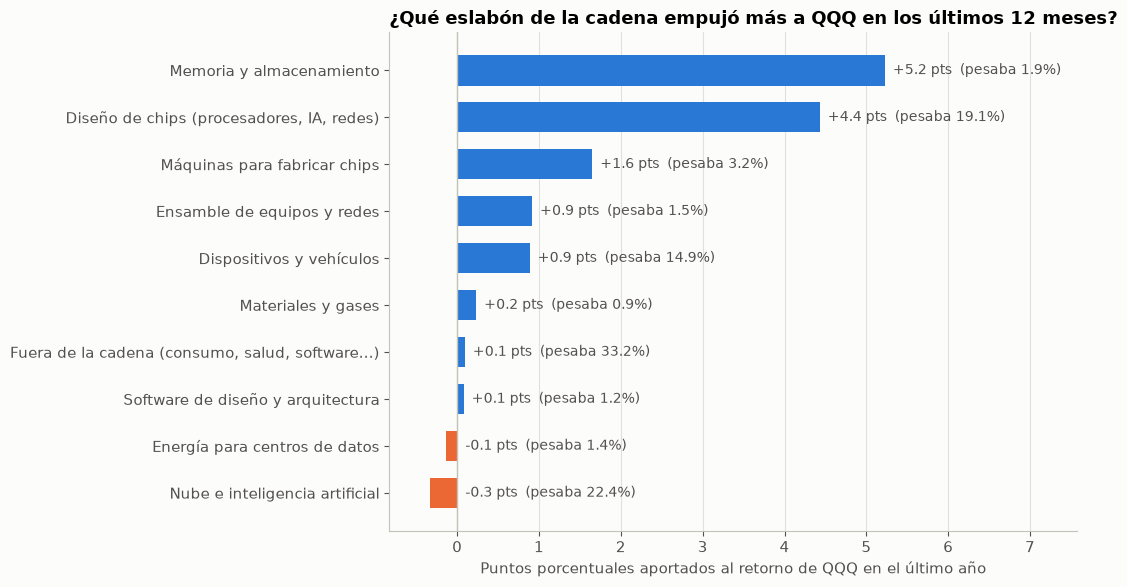

In [24]:
datos = por_eslabon.iloc[::-1]
colores = [AZUL if v >= 0 else "#eb6834" for v in datos["contribucion_pts"]]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(datos.index, datos["contribucion_pts"], color=colores, height=0.65)
for y_pos, (valor, peso) in enumerate(zip(datos["contribucion_pts"], datos["peso_inicio_pct"])):
    ax.text(max(valor, 0) + 0.1, y_pos, f"{valor:+.1f} pts  (pesaba {peso:.1f}%)",  # las negativas también a la derecha del cero
            va="center", ha="left", color=TEXTO, fontsize=10)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel(f"Puntos porcentuales aportados al retorno de {TICKER} en el último año")
ax.set_title("¿Qué eslabón de la cadena empujó más a QQQ en los últimos 12 meses?", loc="left")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlim(min(0, datos["contribucion_pts"].min()) - 0.5, datos["contribucion_pts"].max() * 1.45)
plt.tight_layout()
plt.show()

In [25]:
columnas = ["empresa", "eslabon", "peso_inicio_pct", "peso_pct", "retorno_1a_pct", "contribucion_pts"]
print("Las 10 empresas que más aportaron:")
display(contrib.sort_values("contribucion_pts", ascending=False).head(10)[columnas].round(2).set_index("empresa"))
print("Las 5 empresas que más restaron:")
display(contrib.sort_values("contribucion_pts").head(5)[columnas].round(2).set_index("empresa"))

Las 10 empresas que más aportaron:


,eslabon,peso_inicio_pct,peso_pct,retorno_1a_pct,contribucion_pts
empresa,,,,,
Micron Technology Inc,Memoria y almacenamiento,1.25,4.36,295.83,3.68
Advanced Micro Devices Inc,"Diseño de chips (procesadores, IA, redes)",2.13,3.71,97.10,2.07
Apple Inc,Dispositivos y vehículos,7.14,8.08,27.94,1.99
Intel Corp,"Diseño de chips (procesadores, IA, redes)",1.38,2.01,64.44,0.89
Sandisk Corp,Memoria y almacenamiento,0.16,0.80,477.38,0.75
Cisco Systems Inc,Ensamble de equipos y redes,1.44,1.85,45.60,0.65
Palo Alto Networks Inc,"Fuera de la cadena (consumo, salud, software…)",0.93,1.36,66.12,0.61
Texas Instruments Inc,"Diseño de chips (procesadores, IA, redes)",0.68,1.14,90.38,0.61
Applied Materials Inc,Máquinas para fabricar chips,0.89,1.32,68.27,0.61


Las 5 empresas que más restaron:


,eslabon,peso_inicio_pct,peso_pct,retorno_1a_pct,contribucion_pts
empresa,,,,,
Netflix Inc,"Fuera de la cadena (consumo, salud, software…)",2.47,1.21,-44.51,-1.10
AppLovin Corp,"Fuera de la cadena (consumo, salud, software…)",1.10,0.35,-64.15,-0.71
Space Exploration Technologies Corp,Dispositivos y vehículos,3.75,2.78,-16.30,-0.61
Tesla Inc,Dispositivos y vehículos,4.01,3.11,-12.43,-0.50
Intuit Inc,"Fuera de la cadena (consumo, salud, software…)",0.89,0.41,-48.18,-0.43


### 3.5 Conclusiones de la cadena de suministro
Datos de los últimos 12 meses, hasta el cierre del 30 de octubre de 2026.

1. **La cadena explica casi todo el retorno del fondo.** QQQ subió **10.3%** en el año. Las empresas de la cadena de suministro, que pesaban el **66.6%** del fondo al inicio, aportaron **12.9 puntos**; las otras 60 empresas (consumo, salud, software, el 33% del peso) sumaron apenas **0.1 puntos**, porque sus ganancias y pérdidas se cancelaron. La suma de contribuciones (13.0) es mayor que el retorno real porque es una aproximación (ver 3.4), pero la conclusión no cambia: **lo que mueve a QQQ es la cadena de los chips**.
2. **La memoria fue el eslabón estrella.** Con solo el **1.9%** del peso al inicio, aportó **5.2 puntos**, el 40% del total. Micron subió **296%** y por sí sola aportó 3.7 puntos; Sandisk subió 477%. Es la *causa 5* (ciclo de precios de la memoria) en acción: la demanda de memoria para inteligencia artificial generó escasez y subieron los precios. Por eso Micron pasó de pesar 1.3% a 4.4% del fondo y hoy es la quinta empresa más grande.
3. **El efecto se transmitió a lo largo de la cadena, como en el ejemplo de la parte 3.1.** Después de la memoria, el **diseño de chips** aportó 4.4 puntos (AMD +97%, Intel +64%, Texas Instruments +90%) y las **máquinas para fabricar chips** 1.7 puntos (Applied Materials +68%). La inversión en IA (*causa 2*) se convirtió en ventas para los proveedores de cada eslabón.
4. **La paradoja: quien gasta en IA no fue quien ganó.** El eslabón **nube e inteligencia artificial** (Microsoft, Amazon, Google, Meta) es el más grande del fondo (22.4% del peso), pero aportó **−0.3 puntos**. Su gasto en centros de datos es un **costo** para ellas y un **ingreso** para sus proveedores: el dinero viaja hacia atrás en la cadena (flecha azul punteada del diagrama). El mercado premió a quien vende los chips y castigó la duda sobre si ese gasto será rentable.
5. **Los dispositivos quedaron casi neutros (+0.9 puntos).** Apple subió 28% y aportó 2.0 puntos, pero Tesla (−12%) y SpaceX (−16% desde que empezó a cotizar) restaron. La energía para centros de datos restó levemente (−0.1 puntos).
6. **Fuera de la cadena hubo ganadores y perdedores fuertes que se anularon.** Ciberseguridad subió (Palo Alto +66%, CrowdStrike +84%), mientras Netflix (−45%), AppLovin (−64%) e Intuit (−48%) fueron las que más restaron a todo el fondo.
7. **Riesgo de concentración.** Dos tercios del fondo dependen de una sola cadena, y el eslabón que más empujó, la memoria, es el más **cíclico**: si la escasez se convierte en exceso de oferta, el mismo eslabón puede pasar a restar mucho. A eso se suman riesgos que el fondo no puede diversificar porque están fuera de él, como TSMC en Taiwán (*causa 4*).
8. **Esto explica por qué fallan los modelos de la parte 2.** Lo que movió a QQQ fueron hechos de la industria (gasto en IA, precios de la memoria, controles de exportación), que no están en los precios pasados. Para anticipar a QQQ conviene seguir: los anuncios de inversión de las grandes tecnológicas, los resultados y precios de Micron y la memoria, las decisiones de la Reserva Federal (*causa 1*) y las noticias de aranceles y de Taiwán.


## 4. Conclusión general
1. **QQQ es, en la práctica, una inversión en la cadena de la inteligencia artificial y los semiconductores.** Aunque tiene 100 empresas, 11 explican la mitad del fondo, el 58% es tecnología y dos tercios del peso pertenecen a una misma cadena de suministro, que en el último año generó prácticamente todo el retorno.
2. **No se puede predecir con precisión con datos de precio.** Ninguno de los cinco modelos le ganó de forma clara al modelo ingenuo (el promedio histórico). El pronóstico útil es un **rango**: a 3 meses, el retorno esperado es de +3% a +8%, con un error típico de ±8 puntos; a 12 meses, de +12% a +25%, con un error típico de ±12 puntos.
3. **Lo que sí se puede entender son las causas.** Las tasas de interés (por el valor presente de flujos lejanos), la inversión en IA de las grandes tecnológicas, el ciclo de la memoria, los controles de exportación y el riesgo en Taiwán son los factores que mueven el precio, y la contribución por eslabón confirma con datos cuáles empujaron este año.
4. **Desde la ingeniería económica**, QQQ es un instrumento barato (gasto anual de 0.18%) y muy líquido, con poca renta por dividendos (0.42%), más riesgo que el mercado (beta 1.2) y caídas históricas de hasta un tercio de su valor (2022). Es adecuado para un horizonte largo y un inversionista que tolere esa volatilidad, no para quien necesite el dinero en pocos meses.
